<div style="width: 100%; clear: both;">
<div style="float: left; width: 50%;">
<img src="http://www.uoc.edu/portal/_resources/common/imatges/marca_UOC/UOC_Masterbrand.jpg" align="left">
</div>
<div style="float: right; width: 50%;">
<p style="margin: 0; padding-top: 22px; text-align:right;">M2.891 · Aprendizaje automático · PEC2</p>
<p style="margin: 0; text-align:right;">2026-1 · Máster universitario en Ciencia de datos (Data science)</p>
<p style="margin: 0; text-align:right; padding-button: 100px;">Estudios de Informática, Multimedia y Telecomunicación</p>
</div>
</div>
<div style="width:100%;">&nbsp;</div>
<br>

**Importante:** cada uno de los ejercicios puede suponer varios minutos de ejecución, por lo que la entrega debe hacerse en formato notebook y en formato html, donde se vea el código, los resultados y comentarios de cada ejercicio. Se puede exportar el notebook a html desde el menú File $\to$ Download as $\to$ HTML.

**Importante:** existe un tipo de celda especial para albergar texto. Este tipo de celda os será muy útil para responder a las diferentes preguntas teóricas planteadas a lo largo de cada PEC. Para cambiar el tipo de celda a este tipo, elegid en el menú: Cell $\to$ Cell Type $\to$ Markdown.

**Importante:** la solución planteada no debe utilizar métodos, funciones o parámetros declarados "deprecated" en futuras versiones.

**Importante:** es conveniente que utilicéis una semilla con un valor fijo (en este Notebook se os propone la variable _seed_ inicializada a 100) en todos aquellos métodos o funciones que contengan alguna componente aleatoria para aseguraros de que obtendréis siempre el mismo resultado en las distintas ejecuciones de vuestro código.

**Importante:** no olvidéis poner vuestro nombre y apellidos en la siguiente celda.

<div style="background-color: #ff9999; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>AVISO:</strong> tened cuidado, más podría ser menos. Si os excedéis en las respuestas, podríais tener penalización en la nota. Sed concisos, sintetizad lo que queréis remarcar e id al grano por favor.
</div>

<div class="alert alert-block alert-info">
<strong>Nombre y apellidos:</strong>
</div>


# PEC 2 De la geometría a las decisiones
## Descubrir grupos que permiten tomar decisiones

En esta práctica estudiarás cómo cambian los grupos cuando cambia el algoritmo (1) **y cuando cambia la representación** (2).

1. Laboratorio de clustering.
2. ¿Qué arreglamos en la próxima release? Análisis de comentarios de videojuegos.

Todas las figuras deben elaborarse con **Matplotlib**. Usa títulos, ejes y leyendas legibles. Representa el ruido en gris.

**En el segundo ejercicio**:
 - El uso de MiniLM y Laya es para producir features, no es necesario entrenar ni ajustar sus pesos.
 - Se adjunta un CSV que contiene 2000 comentarios reales.
 - La inferencia en CPU puede tardar bastantes minutos, mide primero el piloto de veinte textos y planifica la ejecución (puedes reducir el número de muestras a 1000 si es excesivo en tu máquina).
 - La variable `N_REVIEWS` permite seleccionar un número de muestras para usar en el ejercicio, no la reduzcas a mitad del experimento.

In [1]:
from pathlib import Path
import gc
import json
import time
import truststore
truststore.inject_into_ssl()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from umap import UMAP
from sklearn.metrics import adjusted_rand_score, silhouette_score, normalized_mutual_info_score
from sklearn.preprocessing import normalize

seed = 100
rng = np.random.default_rng(seed)
threadpool_limits(limits=4)
DATA = Path('.')
CACHE = Path('_pec2_cache')
CACHE.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',None)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 12,
                     'axes.labelsize': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})

/opt/anaconda3/envs/pec2_20261/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Funciones auxiliares para la PEC en las que te puedes apoyar (no es obligatorio usarlas). Las funciones están muy documentadas para facilitar su uso, no estamos esperando que documentes el código de la misma manera.

In [2]:
from pathlib import Path
import hashlib
import json
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


COLORS = ['#2563eb', '#f59e0b', '#059669', '#db2777', '#7c3aed', '#0891b2',
          '#ea580c', '#65a30d', '#475569', '#c026d3', '#0d9488', '#9333ea']


def complaint_question(aspect, complaint_examples):
    """Construye una pregunta binaria sobre una queja para Laya.

    Parámetros
    ----------
    aspect : str
        Aspecto en inglés que se quiere detectar (por ejemplo, "performance").
    complaint_examples : str
        Descripción en inglés de la queja.

    Return
    ------
    dict
        Esquema de respuesta binaria de Laya, con alternativas explícitas de queja y ausencia de queja.

    Ejemplo
    -------
    >>> questions = {"performance": complaint_question(
    ...     "performance", "Low FPS, stuttering or excessive lag.")}
    >>> features = laya_features(agent, df["text"], questions)
    """
    return {
        'type': 'noul',
        'instructions': f'Does this game review complain about {aspect}?',
        'labels': {'false': f'No {aspect} complaint', 'true': f'{aspect} complaint'},
        'criteria': {'false': f'{aspect} is praised or unmentioned; no complaint.',
                     'true': complaint_examples},
    }


def plot_groups(ax, xy, labels, title, size=16):
    """Scatter plot bidimensional con los puntos coloreados por grupo.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Eje en el que se dibuja.
    xy : numpy.ndarray con shape (n_muestras, 2)
        Coordenadas originales o proyección UMAP.
    labels : array de enteros de longitud n_muestras
        Grupo de cada punto, en el mismo orden que xy. El valor -1 representa ruido y se dibuja en gris. Los demás grupos usan la paleta COLORS.
    title : str
        Título de la figura.
    size : float, opcional
        Área de los marcadores en puntos cuadrados.

    Return
    ------
    None
        Modifica ax.

    Ejemplo
    -------
    >>> fig, ax = plt.subplots()
    >>> plot_groups(ax, xy, labels, "Grupos en UMAP")
    >>> ax.legend()
    >>> plt.show()
    """
    labels = np.asarray(labels)
    for label in sorted(np.unique(labels)):
        mask = labels == label
        color = '#a1a1aa' if label == -1 else COLORS[int(label) % len(COLORS)]
        ax.scatter(xy[mask, 0], xy[mask, 1], s=size, color=color, alpha=.75,
                   edgecolors='none', label='Ruido' if label == -1 else f'Grupo {label}')
    ax.set_title(title, fontweight='bold', pad=10)
    ax.set_xlabel('Coordenada 1')
    ax.set_ylabel('Coordenada 2')
    ax.spines[['top', 'right']].set_visible(False)


def heatmap(ax, matrix, rows, columns, title, cmap='Blues', vmin=0, vmax=1, annotate=True):
    """Mapa de calor con etiquetas y valores.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Eje en el que se dibuja.
    matrix : array de forma (n_filas, n_columnas)
        Valores.
    rows, columns : secuencias de str
        Etiquetas de filas y columnas (su longitud debe coincidir con la matrix).
    title : str
        Título del mapa de calor.
    cmap : str, opcional
        Paleta de Matplotlib.
    vmin, vmax : float, opcional
        Límites de la escala de color (por defecto, 0 y 1).
    annotate : bool, opcional
        Si es True, escribe cada valor con dos decimales.

    Return
    ------
    matplotlib.image.AxesImage
        Imagen que permite añadir una barra de color con fig.colorbar().

    Ejemplo
    -------
    >>> fig, ax = plt.subplots()
    >>> im = heatmap(ax, [[0.2, 0.8]], ["Grupo 0"],
    ...              ["Bugs", "Rendimiento"], "Perfil del grupo")
    >>> fig.colorbar(im, ax=ax)
    >>> plt.show()
    """
    matrix = np.asarray(matrix)
    im = ax.imshow(matrix, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(columns)), columns, rotation=35, ha='right')
    ax.set_yticks(range(len(rows)), rows)
    ax.set_title(title, fontweight='bold', pad=12)
    if annotate:
        for i in range(len(rows)):
            for j in range(len(columns)):
                ax.text(j, i, f'{matrix[i, j]:.2f}', ha='center', va='center',
                        color='white' if matrix[i, j] > (vmin + vmax) / 2 else '#18181b', fontsize=9)
    return im


def show_representatives(df, vectors, labels, max_groups=4, n=3):
    """Muestra comentarios cercanos al centro de los grupos más numerosos.

    Parámetros
    ----------
    df : pandas.DataFrame
        Comentarios con columnas review_id, game y text.
    vectors : array con shape (n_comentarios, n_variables)
        Representación usada para calcular la media de cada grupo y la distancia euclídea a ella.
    labels : array de longitud n_comentarios
        Etiquetas del clustering.
    max_groups : int, opcional
        Número máximo de grupos que se muestran.
    n : int, opcional
        Número máximo de comentarios que se imprimen por grupo.

    Return
    ------
    None
        
    Ejemplo
    -------
    >>> show_representatives(df, embeddings, labels, max_groups=4, n=3)
    """
    vectors, labels = np.asarray(vectors), np.asarray(labels)
    counts = pd.Series(labels[labels >= 0]).value_counts()
    for label in counts.head(max_groups).index:
        positions = np.flatnonzero(labels == label)
        mean = vectors[positions].mean(axis=0)
        order = positions[np.argsort(np.linalg.norm(vectors[positions] - mean, axis=1))[:n]]
        print(f'\nCLUSTER {label} | {len(positions)} comentarios')
        for position in order:
            row = df.iloc[position]
            print(f"  {row.review_id} · {row.game}\n  {textwrap.fill(row.text, width=100)}\n")


def laya_features(agent, texts, questions, cache_dir=Path('_pec2_cache/laya')):
    """Extrae features numéricas con Laya y guarda resultados.

    Parámetros
    ----------
    agent : agente Laya
        Modelo cargado con load_laya().
    texts : iterable de str
        Textos que se procesan en el orden recibido.
    questions : dict
        Nombres de preguntas y sus esquemas Laya. Admite "noul", "score" y "choice".
        Los nombres de las columnas resultantes deben ser únicos.
    cache_dir : str o pathlib.Path, opcional
        Carpeta de caché que se crea si no existe (como tarda bastante evita recálculos).

    Return
    ------
    pandas.DataFrame
        Una fila por texto, en el orden de entrada, con índice nuevo desde cero.
        
    Ejemplo
    -------
    >>> questions = {"performance": complaint_question(
    ...     "performance", "Low FPS, stuttering or excessive lag.")}
    >>> features = laya_features(agent, df["text"], questions)
    >>> features.head()
    """
    from importlib.metadata import version
    import time
    started = time.perf_counter()
    texts = list(texts)
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    identity = {'questions': questions, 'laya_version': version('laya'),
                'checkpoint': getattr(agent, '_pec2_revision', 'unspecified')}
    schema_hash = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:20]
    path = cache_dir / f'laya_{schema_hash}.json'
    cache = json.loads(path.read_text(encoding='utf-8')) if path.exists() else {'identity': identity, 'rows': {}}
    hits = sum(hashlib.sha256(text.encode('utf-8')).hexdigest() in cache['rows'] for text in texts)
    records = []
    keys = [column for key,q in questions.items()
            for column in (list(q['criteria']) if q['type']=='choice' else [key])]
    if len(keys)!=len(set(keys)):
        raise ValueError('Usa nombres de opciones únicos entre preguntas choice.')
    for text in tqdm(list(texts), desc='Laya: features', leave=True, mininterval=15):
        text_hash = hashlib.sha256(text.encode('utf-8')).hexdigest()
        if text_hash not in cache['rows']:
            response = agent.predict(text, questions)
            answers = response['answers']
            values = []
            for key in questions:
                if questions[key]['type'] == 'noul':
                    new_values = [float(answers[key]['noul'])]
                elif questions[key]['type'] == 'score':
                    new_values = [float(answers[key]['score']) / (len(questions[key]['criteria']) - 1)]
                elif questions[key]['type'] == 'choice':
                    new_values = [float(answers[key]['probabilities'][option]) for option in questions[key]['criteria']]
                else:
                    raise ValueError('Use choice, noul o score para obtener features numéricas.')
                if any(not np.isfinite(v) or not 0 <= v <= 1 for v in new_values):
                    raise ValueError(f'Salida fuera de rango para {key}: {new_values}')
                values.extend(new_values)
            cache['rows'][text_hash] = values
            temporary = path.with_suffix('.tmp')
            temporary.write_text(json.dumps(cache, ensure_ascii=False), encoding='utf-8')
            for attempt in range(10):
                try:
                    temporary.replace(path)
                    break
                except PermissionError:
                    if attempt == 9:
                        raise
                    time.sleep(.05 * (attempt + 1))
        records.append(cache['rows'][text_hash])
    print(f'Cache: {hits}/{len(texts)}; inferencias nuevas: {len(texts)-hits}; tiempo: {time.perf_counter()-started:.1f} s')
    return pd.DataFrame(records, columns=keys, dtype=float)


def load_laya(revision, device='cpu'):
    """Carga la variante typed-decisions de Laya en el dispositivo indicado.

    Parámetros
    ----------
    revision : str
        Revisión del repositorio convaiinnovations/laya.
    device : str, opcional
        Dispositivo de PyTorch ("cpu" por defecto). Si tienes GPU con cuda puedes usar "cuda".

    Return
    ------
    agente Laya
        Modelo con método predict() y revisión registrada para laya_features().
        
    Ejemplo
    -------
    >>> agent = load_laya(revision="7b928d828b7b0e022f929d9bd2e44165aa270148")
    >>> features = laya_features(agent, df["text"], questions)
    """
    import laya
    agent = laya.load('convaiinnovations/laya', subfolder='typed-decisions', device=device, revision=revision)
    agent._pec2_revision = revision + '/typed-decisions'
    return agent

 
# 1. Laboratorio de clustering (4 puntos)

Vamos a usar datasets sintéticos para comprender cómo se comportan los distintos algoritmos.
Las etiquetas se usan únicamente para visualizar y evaluar. Es algo que, a priori, no tendrás en un entorno real.

## 1.1 Predecir los resultados

El código siguiente genera cuatro casos con 400 muestras cada uno. Utiliza el mismo generador y semilla durante todo el ejercicio.

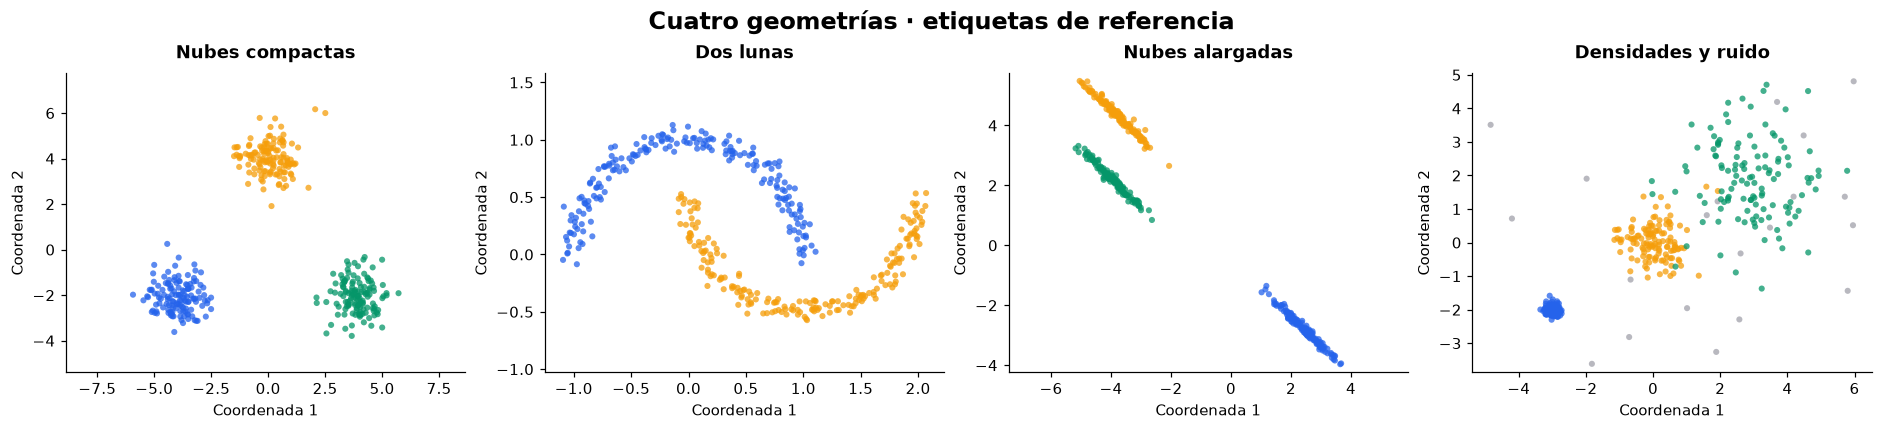

In [3]:
X_blobs, y_blobs = make_blobs(n_samples=400, centers=[(-4,-2),(0,4),(4,-2)],
                              cluster_std=.65, random_state=seed)
X_moons, y_moons = make_moons(n_samples=400, noise=.055, random_state=seed)
X_aniso, y_aniso = make_blobs(n_samples=400, centers=3, cluster_std=.65, random_state=seed)
X_aniso = X_aniso @ np.array([[.7, -.6], [-.4, .5]])
X_density, y_density = make_blobs(n_samples=[130,130,120],
    centers=[(-3,-2),(0,0),(3,2)], cluster_std=[.12,.5,1.05], random_state=seed)
X_density = np.vstack([X_density, rng.uniform([-5,-4],[6,5], size=(20,2))])
y_density = np.r_[y_density, np.full(20, -1)]
synthetic = {'Nubes compactas': (X_blobs,y_blobs), 'Dos lunas': (X_moons,y_moons),
             'Nubes alargadas': (X_aniso,y_aniso), 'Densidades y ruido': (X_density,y_density)}

fig, axes = plt.subplots(1,4,figsize=(17,3.8), layout='constrained')
for ax, (name,(X,y)) in zip(axes, synthetic.items()):
    plot_groups(ax,X,y,name)
    ax.set_aspect('equal', adjustable='datalim')
fig.suptitle('Cuatro geometrías · etiquetas de referencia', fontsize=16, fontweight='bold')
plt.show()


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Completa la tabla de respuesta para los cuatro casos y K-means, DBSCAN, Ward y single linkage. Predice si, para cada dataset, el modelo es capaz de encontrar las componentes de la estructura, justifica cada fila con la dificultad del dataset. ¿Qué métodos obligan a indicar el número de grupos y cuáles pueden identificar ruido?</div>

| Caso | K-means | DBSCAN | Ward | Single linkage | Particularidad del dataset |
|---|---|---|---|---|---|
| Nubes compactas | | | | | |
| Dos lunas | | | | | |
| Nubes alargadas | | | | | |
| Densidades y ruido | | | | | |

 
## 1.2 Elegir el número de grupos

Analiza y agrupa las siguientes **nubes compactas**. Este código proporcionado muestra los datos sin sus etiquetas de referencia.

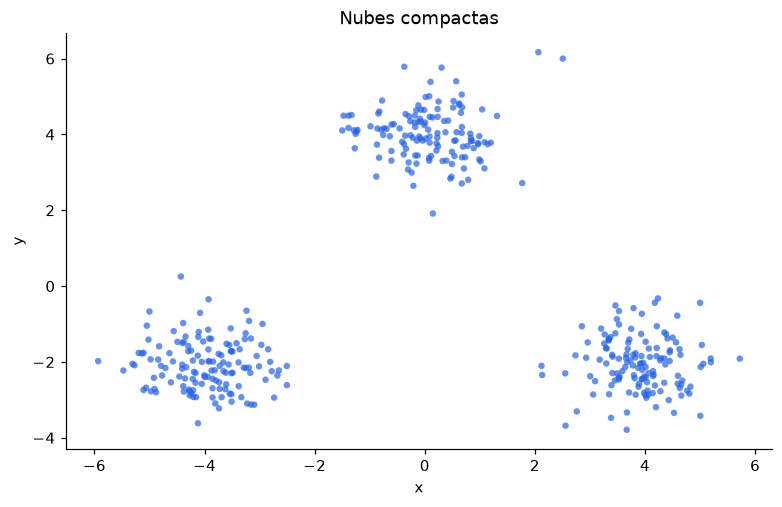

In [4]:
X_blobs, y_blobs = make_blobs(n_samples=400,centers=[(-4,-2),(0,4),(4,-2)], cluster_std=.65,random_state=seed)
fig,ax = plt.subplots(figsize=(7,4.5), layout='constrained')
ax.scatter(X_blobs[:,0], X_blobs[:,1], s=18, color=COLORS[0], alpha=.7, edgecolors='none')
ax.set(title='Nubes compactas', xlabel='x', ylabel='y')
plt.show()


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Sobre las nubes compactas, prueba <code>k=2,...,7</code>. Representa en tres subplots la inercia (SSE), el silhouette y el resultado de la agrupación en el dataset (elige un valor de <code>k</code>).</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Interpreta las curvas del punto anterior. ¿Por qué la SSE siempre puede mejorar al aumentar <code>k</code>? ¿Un silhouette alto asegura que los grupos coinciden con el significado que buscamos?</div>

 
## 1.3 Comparar cuatro estrategias

Utiliza K-means, DBSCAN y aglomerativo (con enlaces Ward y single). Como K-means y el aglomerativo requieren el número de clusters, usa tres grupos, excepto en las lunas, ahí selecciona dos. Para DBSCAN prueba como máximo seis valores de `eps` por dataset y fija `min_samples=5`. Justifica tu elección mediante las vecindades y los gráficos.

Para entender si las estructuras descubiertas por los algoritmos se corresponden con las esperadas usaremos el **[ARI](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html) (*Adjusted Rand Index*)**, que mide la coincidencia entre dos particiones (los grupos encontrados y las etiquetas del dataset).

Incluye todos los puntos al calcularlo e indica el porcentaje de ruido (eliminarlo podría ocultar fallos).

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Vamos a implementar la tabla del apartado 1.1. Ajusta cada dataset con los 4 métodos y construye una figura de 4 × 4 subplots (datasets × algoritmos) para visualizarlo, una tabla con número de grupos, porcentaje de ruido y ARI, y un mapa de calor de ARI. Indica los parámetros elegidos en los modelos.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Coincide con tus predicciones? </div>

 
## 1.4 La diferencia entre Ward y Single

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> En el dataset de las lunas, representa dendrogramas con enlaces Ward y single sobre una submuestra (la misma para ambos métodos) de 80 puntos. En el dataset de densidades, representa en otros dos subplots cómo varía el número de grupos y el porcentaje de ruido con valores de <code>eps de {0.10, 0.20, 0.35, 0.50, 0.80, 1.20}</code>.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Por qué dos enlaces generan dendrogramas distintos? ¿Puede el número de grupos detectados por DBSCAN ser igual al esperado y, aun así, haber descartado gran parte de los datos?</div>


## 1.5 Feature engineering para agrupar datos

En el dataset de los dos círculos concéntricos empezaremos usando las coordenadas cartesianas `(x,y)`. Comprueba si conocer el número correcto de grupos basta para recuperar los dos círculos.

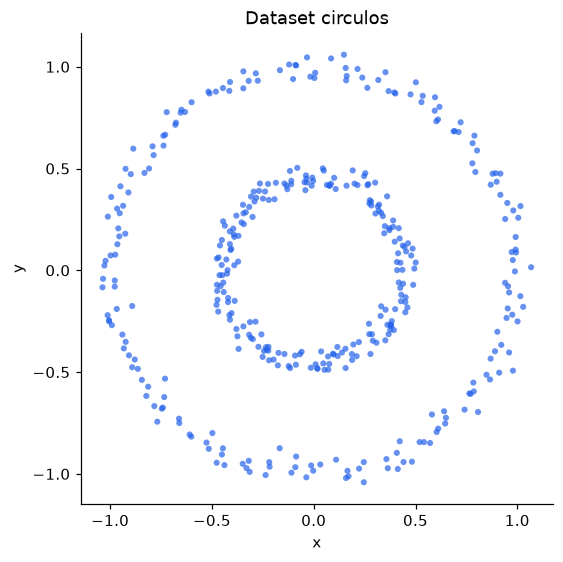

In [8]:
X_rings,y_rings = make_circles(n_samples=400, factor=.45, noise=.035, random_state=seed)
fig,ax = plt.subplots(figsize=(5.5,5), layout='constrained')
ax.scatter(X_rings[:,0], X_rings[:,1], s=16, color=COLORS[0], alpha=.7, edgecolors='none')
ax.set(title='Dataset circulos', xlabel='x', ylabel='y')
ax.set_aspect('equal')
plt.show()

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Aplica K-means con <code>k=2</code> sobre las coordenadas originales. Representa los grupos y calcula ARI respecto a los dos círculos de referencia.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Recupera K-means los dos círculos? Explica el fallo a partir de sus centroides y de la distancia euclídea. ¿Cómo intentarías solucionarlo? ¿Cambiarías de algoritmo? Propón una alternativa y justifícala antes de continuar.</div>


### Transformación del dato

Vamos a mantener el algoritmo, pero transformando los datos.
El centro de generación conocido de estos círculos es `(0,0)`. Calcula una única feature: el **radio**. Es decir, la distancia de cada punto al origen:

$$r_i = \sqrt{x_i^2+y_i^2}.$$

Dos puntos en posiciones opuestas del mismo círculo están lejos en `(x,y)`, pero tienen radios parecidos.
Vamos a comprobar si esta feature permite separar los dos círculos usando la distancia al origen `(0,0)`.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Crea el nuevo dataset donde, para cada muestra, en lugar de representarla con x e y, sea su radio. Aplica K-means con <code>k=2</code> solo a la columna radio. Grafica el dataset original coloreando los puntos con el resultado de la agrupación de K-means sobre el dato inicial (x,y) con su ARI, también el dataset original pero coloreando las muestras con la agrupación por radio (la nueva feature) con su ARI, y los histogramas de la variable radio para cada una de las etiquetas originales.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Han cambiado las etiquetas encontradas? ¿Y el ARI? ¿Por qué?</div>


# 2. ¿Qué arreglamos en la próxima release? (6 puntos)

Trabajas con el equipo de calidad de un estudio de videojuegos. El equipo quiere entender qué **familias de problemas** están experimentando los usuarios para solventarlos, a partir de muchos comentarios escritos con vocabularios distintos. Los comentarios positivos también aportan contexto: no toda mención de rendimiento o dificultad es una queja.

En la primera parte agruparás por similitud general del texto con **MiniLM**. En la segunda, construirás nuevas features con **Laya**, un modelo de decisiones, y comprobarás si los grupos resultan más fáciles de interpretar para nuestro objetivo.

## Dataset: comentarios históricos de Steam

`steam_reviews_pec2.csv` contiene **2.000 comentarios reales distintos (en inglés) de doce videojuegos**, extraídos del corpus histórico
de Steam del grupo de Julian McAuley. Steam permite recomendar o no recomendar un juego y escribir un comentario libre.
Los comentarios combinan felicitaciones, críticas, humor, sarcasmo y varios problemas en un mismo comentario (con partes positivas y negativas).

Puedes consultar la [descripción del dataset Steam](https://cseweb.ucsd.edu/~jmcauley/datasets.html#steam_data)
y descargar el [archivo original](https://mcauleylab.ucsd.edu/public_datasets/data/steam/australian_user_reviews.json.gz).
Los [metadatos originales de juegos](https://cseweb.ucsd.edu/~wckang/steam_games.json.gz) se usan únicamente para añadir los títulos.

| Columna | Descripción y uso en la PEC |
|---|---|
| `review_id` | Identificador del comentario |
| `game_id`, `game` | Identificador del juego y título (para hacerlo interpretable) |
| `text` | Comentario original **será la entrada para MiniLM y Laya** |
| `recommend` | Recomendación original del autor |

## 2.1 Familiarizarnos con los comentarios

Campos: `review_id`, `game_id`, `game`, `text`, `recommend`. Utiliza solamente `text` como entrada de los modelos.
El nombre del juego y la recomendación se reservan para el análisis posterior, no son etiquetas del problema que queremos descubrir.

Puede que al procesar los comentarios tarde bastante tiempo, en la siguiente celda hemos dejado una constante *N_REVIEWS* que puedes disminuir para acelerar el proceso. Pero hará más difícil ver los resultados de los apartados.

In [11]:
raw = pd.read_csv(DATA/'steam_reviews_pec2.csv',dtype={'review_id':str,'game_id':str})
assert len(raw) == 2000

N_REVIEWS = 2000
print('Comentarios en el extracto:',len(raw))
display(raw[['review_id','game','text']].head(3))

Comentarios en el extracto: 2000


,review_id,game,text
0,S0000,Team Fortress 2,I enjoy playing dress-up with grown men.I enjoy killing dressed-up grown men.I enjoy dancing around on the battlefield with dressed-up grown men.I enjoy getting killed by dressed-up grown men.I enjoy wasting money to buy cosmetics for grown men.10/10 Would waste money again. :)
1,S0001,Loadout,"A game if you want to just shoot and shoot and not do much else. Yeah, 26 minutes was about all I could stand, obviously not my cup of tea."
2,S0002,Unturned,"Indeed a lot of fun. It can kinda be annoying that you can get killed so easily, but that could be just that i suck at the game xD. Buy it, it's really a lot of fun!"


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Limpia vacíos y duplicados, utiliza los 2.000 comentarios o reduce <code>N_REVIEWS</code> a 1.000 si la ejecución es lenta. Usa la semilla común para que el muestreo sea reproducible. Guárdala como <code>reviews</code>. Representa en dos gráficas: la longitud de los textos y el número de comentarios por juego.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Lee cinco comentarios. ¿Qué ambigüedades encuentras?</div>


## 2.2 Representación inicial: similitud general del texto

### ¿Qué es MiniLM?

MiniLM es una familia de modelos compactos de lenguaje basada en Transformers (como los GPTs). En esta PEC utilizamos
[`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), adaptado para representar
frases y párrafos como **embeddings de 384 dimensiones** (una representación vectorial del comentario) que resume relaciones aprendidas entre textos. En la práctica, comentarios de significado parecido deberían estar cerca en este espacio, aunque no utilicen exactamente las mismas palabras.

Lo cargaremos con Sentence Transformers y haremos **inferencia**, sin entrenar el modelo. Cada comentario se convierte en una fila de la matriz `E`, con 384 columnas. **Normalizaremos los vectores a norma uno** para comparar direcciones sin que domine su longitud.

Por ejemplo, «se cierra al empezar» y «crashes on startup» pueden tener una relación semántica que un conteo literal de palabras no captura.
Pero la proximidad también puede reflejar el juego, el tono o un elogio que menciona el mismo aspecto que una queja.
**Estos embeddings capturan similitud general, no una definición específica de incidencia**. Todavía no utilizamos features diseñadas para este problema.
La finalidad de esta primera parte es descubrir qué noción de similitud aporta este modelo y dónde resulta insuficiente.

Como no podemos visualizar 384 dimensiones, aplicarás UMAP directamente sobre los embeddings, con distancia coseno para proyectarlos a 2d.
Compara dos configuraciones: vecindades de 15 textos con `min_dist=0.1` y de 30 textos con `min_dist=0.3`.
No interpretes distancias entre islas de UMAP como una escala fiable (es una proyección).
Consulta la [documentación de sus parámetros](https://umap-learn.readthedocs.io/en/latest/parameters.html).
La primera ejecución puede tardar más por la compilación de Numba.

In [13]:
import torch
torch.set_num_threads(4)
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2',device='cpu',revision='1110a243fdf4706b3f48f1d95db1a4f5529b4d41')


W1018 21:41:38.131000 33545 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 17700.39it/s]


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Obtén los embeddings en batches de 16 o 32 y normalízalos a norma uno. Guarda la matriz como <code>E</code>. Representa UMAP a 2D en dos gráficos sin etiquetas de clustering, cada uno con las configuraciones indicadas. Usa <code>metric="cosine"</code>, <code>init="spectral"</code>, <code>n_jobs=1</code> y la semilla de reproducibilidad. Guarda las coordenadas como <code>umap_text</code> y <code>umap_text_smooth</code>.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Las dos figuras tienen la misma estructura? ¿Parece haber grupos útiles? ¿Sobre cuál aplicarías clustering?</div>


## 2.3 Buscando estructuras en los embeddings

Aplica K-means a `E`. Elige `k` entre `{4,6,8}` mediante silhouette, tamaños e interpretabilidad.
Una vez elegido, conserva el mismo `k` en los siguientes escenarios.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Representa en 3 gráficas: silhouette para los tres valores de <code>k</code>, elige <code>k_text</code> (el seleccionado) y guarda los grupos en <code>labels_text</code>. Muestra el clustering sobre la proyección UMAP. Y la distribución de tamaños de cada cluster.<br>Por último, inspecciona tres comentarios representativos de cada uno de los 4 grupos <code>show_representatives</code>.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Representa en un mapa de calor para cada juego (eje x) y cada cluster (eje y) el porcentaje de comentarios de cada juego (normaliza a 1 cada fila).<br>Calcula el Normalized Mutual Information (NMI) entre cluster y juego como medida de asociación, para saber el grado de correspondencia de los grupos con los juegos.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Asigna un nombre provisional a los 4 grupos inspeccionados. Puedes usar IA para ayudarte a identificar el tema a partir de los comentarios representativos, pero comprueba la propuesta leyendo los textos y cita los identificadores en los que te has basado.</div>

Lee los 20 textos siguientes y anota su problema principal
(rendimiento, errores, dificultad/equilibrio, repetición, multijugador, monetización, otro, sin queja clara o ambigua).
Guarda la tabla `audit` antes de ejecutar el modelo de decisiones.

In [17]:
audit_positions = np.random.default_rng(seed+10).choice(len(reviews),20,replace=False)
audit = reviews.loc[audit_positions,['review_id']].copy()
audit['problem'] = ''
display(reviews.loc[audit_positions,['review_id','text']])

,review_id,text
1840,S0439,"Join the other 8 Million people in world who have no lifes and play the russian simulator that will steal your soul, Dota 2"
1034,S1633,This is a very good game and i recommend it. I also recommend buying all the dlc and future dlc.
1259,S1227,*going tryhard on bank heist deathwish**saw a tazer**got tazed**shotted tons of civil instand of tazer**got downed*10/10 whould get tazed again
1764,S0885,"I could not play this game once because of how laggy and buggy it is...♥♥♥♥ this game its ♥♥♥♥, dont waist your money on it."
1391,S1591,How to be a pro criminalMethod 11. Get in2. Find guards3. Mark them4. Hide5. Steal6. EscapeMethod 21. Get in 2. Start shooting (preferably rockets/grenades/lmg)3. Steal4. Escape10 cocaine packs/10
1844,S1946,Tons of Fun if you can play Toxic players if your new so it's best to start off with some good old fashion Tutorial (League of legends) Can't seem to get reborn to work on mac but eh it'll probs be fixed hopefully....
891,S0557,"Learnt the words ""♥♥♥♥ ♥♥♥♥♥"" and was yelled at by a clan of 10 year olds who pretend they are KennyS.10/10 would spent several hours in bed crying at the red i almost got again"
1016,S1877,hackerstrash-talkersrussians/spanish ♥♥♥♥♥♥♥ some stupid m8's that spent the whole game in base afk smurfs11/10 - IGNwould spent my entire life in this
473,S1979,"Everything is amazing in this game, but the only thing I hate is that for Update 3.0 we lose all our ♥♥♥♥! *crying*"
1959,S0603,"This game has always been hit and miss. When it worked, it was quite enjoyable, when it didn't, it was rage-inducing. However, Overkill has clearly made producing DLC and their respective trailers the priority over fixing game-breaking bugs and imbalances. Stat-boosting DLC is the straw that broke the camel's back, IMO. I hope most of you are strong enough to vote with your wallet and boycott Overkill games until they rectify this problem.EDIT: It would actually be Starbreeze calling the shots here, so the boycott should extend to any future titles produced under the Starbreeze umbrella."


<div style="background:#b8e7ff;color:black;padding:1.2em 1.4em;border-radius:8px;">
<strong style="font-size:1.35em;">Ahora vamos a cambiar qué significa "parecerse".</strong><br><br>
Hasta aquí hemos agrupado por similitud general del texto. El equipo necesita encontrar problemas investigables.<br>
Vamos a preguntar a un modelo de decisiones por atributos concretos de cada comentario y volver a agrupar.
</div>

## 2.4 Crear seis features con Laya

### De pedir etiquetas a un LLM a utilizar un modelo de decisiones

Una posibilidad sería enviar cada comentario a un LLM generativo y pedirle que escribiera una etiqueta o un JSON.
Eso permite formular tareas flexibles y pedir explicaciones, pero para este paso solo necesitamos decisiones numéricas con significado estable:
"¿qué problema principal describe?" o "¿hay una queja sobre controles?". Generar una explicación completa para cada comentario no es necesario.

Un LLM generativo produce su respuesta como una secuencia de tokens. Puede utilizar esquemas y decodificación restringida para devolver JSON válido. No hay que confundir validez del formato con un juicio correcto. Un **modelo de decisiones** toma el texto y una pregunta con alternativas o escala, y obtiene directamente las puntuaciones de las respuestas permitidas. Puede incorporarse a un programa como una regla flexible, sin tener que extraer una etiqueta de una respuesta redactada.

**Jev**, de TypeSafe, es un ejemplo de esta idea: decisiones tipadas en lugar de generación libre.
Su documentación presenta el contraste entre generar tokens y producir las puntuaciones de las opciones en paralelo:
[presentación de System One y Jev](https://typesafe.ai/blog/introducing-system-one-models-and-jev).
En esta actividad usaremos **Laya**, una alternativa con pesos disponibles y licencia Apache 2.0, que podemos ejecutar localmente. No necesitaremos una cuenta o una API de Jev.

### Cómo funciona Laya

Usamos el checkpoint inglés `typed-decisions`, técnicamente: basado en un encoder bidireccional ModernBERT-large y una cabeza de decisión,
con unos 421 millones de parámetros. **Combina el estado con las instrucciones y criterios de la pregunta, representa ese contexto
y puntúa las alternativas en una pasada por la red, sin generar una respuesta token a token**.
Esta descripción corresponde al checkpoint elegido. No presupone que todos los modelos de decisiones compartan arquitectura.
Consulta la [ficha de la familia Laya](https://huggingface.co/convaiinnovations/laya) y el [SDK y ejemplos oficiales](https://github.com/NandhaKishorM/laya).

No entrenaremos un clasificador distinto para cada feature: **describiremos su significado en el esquema de la pregunta y aplicaremos el modelo preentrenado**. Lo usaremos como un clasificador *zero-shot* (sin entrenamiento *ad-hoc*).
La definición de las categorías y sus criterios sigue siendo una decisión nuestra. Una salida numérica no elimina ese trabajo de diseño.

Las ventajas para esta práctica son **salida acotada (a lo que especifiquemos), integración sencilla, ejecución local y ausencia de generación innecesaria**,  no es autorregresivo como los LLMs, solo usa una pasada por entrada, lo que acelera y abarata mucho el proceso de etiquetado.
También puede fallar ante sarcasmo, lenguaje informal, varios problemas simultáneos o preguntas mal definidas. Sus puntuaciones tampoco se convierten automáticamente en probabilidades calibradas sobre Steam.

Estamos usando Laya porque se trata de un modelo pequeño que podemos correr en máquinas discretas, hay alternativas más completas. Puedes consultarlas y compararlas en este [leaderboard de modelos de decisión](https://benchmarkheaven.com/jev-models).

### Las seis features propuestas

Laya recibe un **estado** (el comentario) y preguntas con un tipo de respuesta:
`choice` (opción), `score` (escala) o `noul` (sí/no). Usaremos el checkpoint `typed-decisions` y una clasificación `choice`
del **problema principal**. Sus puntuaciones para seis categorías se convierten en features continuas en `[0,1]`.
No deben interpretarse como probabilidades perfectamente calibradas para este dominio.

| Feature | Pregunta de dominio |
|---|---|
| `performance_complaint` | ¿Hay una queja sobre FPS, fluidez o carga? |
| `bugs_complaint` | ¿Describe un error, un bloqueo o un cierre inesperado? |
| `balance_complaint` | ¿Critica dificultad o equilibrio de las mecánicas? |
| `grind_complaint` | ¿Critica repetición o esfuerzo excesivo para avanzar? |
| `multiplayer_complaint` | ¿Describe problemas de conexión, emparejamiento o cooperación? |
| `monetization_complaint` | ¿Critica compras adicionales, DLC o pagar para obtener ventajas? |

Añade además las opciones `other_complaint` y `no_complaint`, para no forzar todo texto a ser una queja de las seis categorías.
**Mencionar un aspecto no equivale a quejarse de él.** Las instrucciones deben indicar esa diferencia.
Las ocho puntuaciones compiten y suman aproximadamente uno, las seis features seleccionadas suman como máximo uno.
No renormalices esas seis columnas: un comentario sin quejas debe conservar puntuaciones pequeñas.
Esta clasificación simplifica comentarios con varios problemas al principal. Es una limitación que debes analizar.
Una única pregunta `choice` resulta más económica en CPU que seis preguntas binarias independientes.
Consulta la [ficha de Laya](https://huggingface.co/convaiinnovations/laya) y su [SDK](https://github.com/NandhaKishorM/laya).

In [19]:
LAYA_REVISION = '7b928d828b7b0e022f929d9bd2e44165aa270148'
agent = load_laya(LAYA_REVISION,device='cpu')

# Ejemplo binario para familiarizarse con el formato choice.
example_questions = {
    'performance_check': {'type':'choice',
        'instructions':'Does this review complain about technical performance?',
        'criteria':{'performance_complaint':'Poor FPS, stuttering or slow loading.',
                    'no_performance_complaint':'Performance praised or unmentioned; no performance complaint.'}}
}
example_text = 'I like the story, but the frame rate drops to 10 FPS and stutters.'
print(agent.predict(example_text,example_questions)['answers'])

Fetching 5 files: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 763.57it/s]
/opt/anaconda3/envs/pec2_20261/lib/python3.12/site-packages/laya/agent.py:2144: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,


{'performance_check': {'type': 'choice', 'choice': 'performance_complaint', 'probabilities': {'performance_complaint': 0.8559, 'no_performance_complaint': 0.1441}, 'confidence': 0.4052, 'answer_confidence': 0.8559, 'action': {'act_probability': 1.0}}}


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Define <code>questions_base</code> con una pregunta <code>choice</code> en inglés y ocho opciones: las seis categorías de la tabla, <code>other_complaint</code> y <code>no_complaint</code>. Escribe criterios claros para cada opción. Obtén las puntuaciones de 20 comentarios, revisa manualmente cuatro aciertos y dos errores o ambigüedades y después procesa la muestra completa con <code>laya_features</code>. Guarda el DataFrame como <code>F_base</code>. Representa en un mapa de calor las puntuaciones de 15 comentarios identificados por <code>review_id</code>.</div>

In [20]:
questions_base = {
    'main_problem': {'type':'choice','instructions':'...',
                     'criteria':{}}
    # Añade las seis categorías propuestas, other_complaint y no_complaint.
}
# Hazlo primero con 20 muestras para validar que todo está bien sin esperar mucho tiempo. Luego con todos los datos.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Encuentras alguna feature casi constante? ¿Hay comentarios positivos clasificados como quejas? Cita dos comentarios concretos y explica cómo un error del clasificador puede alterar las distancias y el clustering.</div>


## 2.5 Tu aportación: al menos una feature nueva

Ahora define **al menos una feature adicional que se obtenga mediante Laya**. Debe aportar información distinta a las seis existentes.
Puedes usar una pregunta `choice` con dos alternativas explícitas, `noul` o una escala `score` con niveles claros.
Si usas una escala, normaliza su resultado a `[0,1]`. `laya_features` devuelve cada opción de `choice` como columna. Si usas `noul`, revisa posibles tendencias a responder sí.

Antes de ejecutar, escribe: nombre, pregunta en inglés, significado de sus valores y una hipótesis sobre qué grupo de comentarios podría ayudar a encontrar.
Justifica su utilidad a partir de ejemplos encontrados en el clustering inicial. El nombre del juego, la recomendación del autor
o una etiqueta final del cluster no son una feature válida para este apartado.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Propón tu feature y una hipótesis concreta. ¿Qué aporta respecto a las seis propuestas? ¿En qué comentarios esperas que ayude y en cuáles podría fallar?</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Define <code>questions_own</code>, ejecuta Laya para esa pregunta sobre la misma muestra y revisa diez ejemplos. Construye <code>F_plus</code> concatenando <code>F_base</code> y las nuevas columnas. Representa un histograma de la nueva feature y los cinco comentarios con mayor puntuación.</div>

In [22]:
questions_own = {
    # Tu pregunta nueva: choice, noul o score.
}
# F_own = laya_features(...)
# F_plus = ...

 
## 2.6 Volver a agrupar: antes, después y tu aportación

Compara **A: embeddings**, **B: seis features** y **C: seis features + la tuya**.
Usa el mismo `k_text`, `n_init=10` y semilla. En B y C conserva las puntuaciones en `[0,1]`:
no estandarices automáticamente una feature casi constante, ya que amplificarías pequeñas variaciones.

El gráfico sobre las coordenadas UMAP iniciales permite observar cómo cambian las asignaciones manteniendo fijo el mapa.
Las proyecciones propias de las features muestran su nueva geometría. Los números y colores de los grupos son arbitrarios entre escenarios.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Calcula <code>labels_base</code> y <code>labels_plus</code> aplicando K-means sobre las features y las features + la tuya. Representa tres gráficas sobre el mismo <code>umap_text</code>, coloreados según A, B y C (misma proyección, distintos colores en base al resultado del K-means).<br>Visualiza en otras dos gráficas las proyecciones UMAP 2D de B y C (esta vez con los vectores obtenidos de Laya) con distancia euclídea, 15 vecinos, <code>min_dist=0.1</code> y la semilla común. Después representa dos mapas de calor de las features medias por grupo, con sus tamaños, y muestra tres comentarios representativos de los 4 grupos más grandes del escenario C.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Completa una tabla de comparación con silhouette (en el espacio propio), NMI cluster/juego y estabilidad entre semillas <code>{100,101,102}</code> (media de ARI entre las tres particiones).<br>Representa en un mapa de calor la transición de comentarios de la agrupación A a B: cada fila suma 1. Comenta qué observaciones cambian de grupo.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Ha mejorado la utilidad del clustering para investigar incidencias? ¿Qué añade tu feature? Propón tres prioridades apoyadas en identificadores concretos de comentarios. Distingue claridad visual, estabilidad y utilidad. No compares silhouette entre espacios como si midiera la misma geometría.</div>

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Qué es mejor, hacer el clustering en alta dimensionalidad o baja? ¿En qué casos puede tener sentido uno u otro?</div>